# Question 3

In [1]:
import copy

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from starter_code.dataloader import HW2Dataset
from starter_code.plotting import plot_surface_2d

### a: Data visualization

In [2]:
ds = HW2Dataset.from_csv("data/Question3/train.csv", "data/Question3/val.csv", "data/Question3/test.csv")

print("train:", ds.train.X.shape, ds.train.y.shape)
print("val:  ", ds.val.X.shape, ds.val.y.shape)
print("test: ", ds.test.X.shape, "| labels:", ds.test.y)
print("x range (train):", ds.train.X.min(axis=0).round(2), "to", ds.train.X.max(axis=0).round(2))
print("y: mean", ds.train.y.mean().round(3), "| sd", ds.train.y.std().round(3))

train: (600, 2) (600,)
val:   (200, 2) (200,)
test:  (200, 2) | labels: None
x range (train): [-3. -3.] to [2.99 2.99]
y: mean 1.533 | sd 1.569


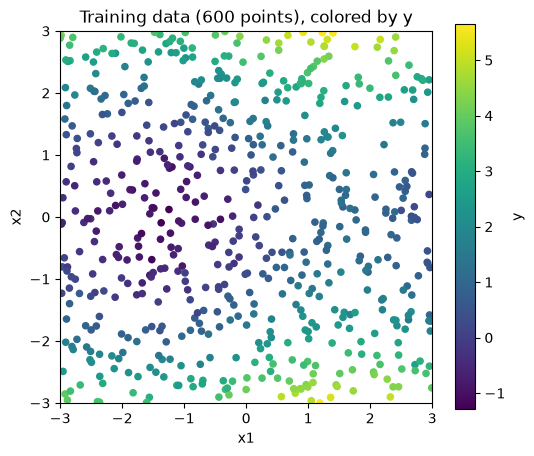

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
points = ax.scatter(ds.train.X[:, 0], ds.train.X[:, 1], c=ds.train.y, cmap="viridis", s=20)
fig.colorbar(points, ax=ax, label="y")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Training data (600 points), colored by y")
plt.show()

Color changes seem mostly continuous when varying $x_1$ and $x_2$. The pattern looks as follows:
- $y$ increases with $\left| x_2 \right|$
- $y$ seems to peak at roughly $x_1 = 1.25$, be smallest around $x_1 = -1.5$, and vary continuously in between these points

Both are nonlinear but seem smooth, hence RKS makes sense

### b: RKS with Ridge Regression

We will vary the kernel scale parameter $\sigma$.

Fixed hyperparameter choices:
- h = 500: large enough so that the model can overfit / memorize everything, hence variation in performance will be due to $\sigma$
- $\lambda$ = 1e-3 for the ridge regression - small so that we can see overfitting

In [4]:
class RandomKitchenSinks:
    """Random sin/cos features of x, then ridge regression with an unpenalized intercept."""
    def __init__(self, D=1000, sigma=1.0, ridge_lambda=1e-3, d=2, seed=0):
        assert D % 2 == 0, "D = 2h must be even (one sin and one cos per frequency)"
        rng = np.random.default_rng(seed)
        self.h = D // 2
        self.W = rng.normal(size=(self.h, d)) / sigma        # w_j ~ N(0, I / sigma^2)
        self.b = rng.uniform(0, 2 * np.pi, size=self.h)     # b_j ~ U[0, 2 pi]
        self.ridge_lambda = ridge_lambda

    def _features(self, X):
        proj = X @ self.W.T + self.b                         # shape (n, h): w_j^T x_i + b_j
        phi = np.hstack([np.sin(proj), np.cos(proj)]) / np.sqrt(self.h)
        return np.hstack([np.ones((len(X), 1)), phi])        # intercept column first: shape (n, D + 1)

    def fit(self, X, y):
        phi = self._features(X)
        penalty = self.ridge_lambda * np.eye(phi.shape[1])
        penalty[0, 0] = 0.0                                  # don't shrink the intercept
        self.coef_ = np.linalg.solve(phi.T @ phi + penalty, phi.T @ y)
        return self

    def predict(self, X):
        return self._features(X) @ self.coef_


def mse(y, pred):
    return np.mean((y - pred) ** 2)

Sweep over values of $\sigma$ that are roughly log-spaced: 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 10, 20

In [5]:
sigmas = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 10, 20]
rks_mse = {"train": [], "val": []}
rks_models = {}

for sigma in sigmas:
    model = RandomKitchenSinks(D=1000, sigma=sigma).fit(ds.train.X, ds.train.y)
    rks_models[sigma] = model
    rks_mse["train"].append(mse(ds.train.y, model.predict(ds.train.X)))
    rks_mse["val"].append(mse(ds.val.y, model.predict(ds.val.X)))
    print(f"sigma = {sigma:>5}: train MSE {rks_mse['train'][-1]:.4f} | val MSE {rks_mse['val'][-1]:.4f}")

best_sigma = sigmas[int(np.argmin(rks_mse["val"]))]
best_rks = rks_models[best_sigma]
print(f"\nbest sigma (lowest validation MSE): {best_sigma}")

sigma =  0.05: train MSE 0.0000 | val MSE 4.5260
sigma =   0.1: train MSE 0.0002 | val MSE 1.0908
sigma =   0.2: train MSE 0.0090 | val MSE 0.1800
sigma =   0.3: train MSE 0.0181 | val MSE 0.0676
sigma =   0.5: train MSE 0.0254 | val MSE 0.0458
sigma =   0.7: train MSE 0.0283 | val MSE 0.0444
sigma =     1: train MSE 0.0297 | val MSE 0.0400
sigma =   1.5: train MSE 0.0308 | val MSE 0.0380
sigma =     2: train MSE 0.0319 | val MSE 0.0368
sigma =     3: train MSE 0.0330 | val MSE 0.0361
sigma =     5: train MSE 0.0347 | val MSE 0.0360
sigma =    10: train MSE 0.0484 | val MSE 0.0529
sigma =    20: train MSE 0.1925 | val MSE 0.1961

best sigma (lowest validation MSE): 5


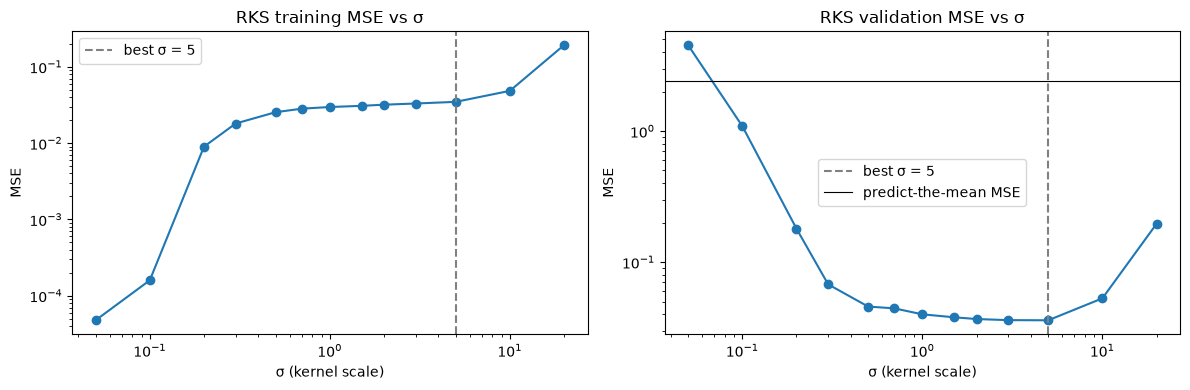

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ["train", "val"]):
    ax.plot(sigmas, rks_mse[split], marker="o")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("σ (kernel scale)")
    ax.set_ylabel("MSE")
    ax.axvline(best_sigma, color="gray", linestyle="--", label=f"best σ = {best_sigma}")
    ax.legend()
axes[0].set_title("RKS training MSE vs σ")
axes[1].set_title("RKS validation MSE vs σ")
axes[1].axhline(ds.val.y.var(), color="black", linewidth=0.8, label="predict-the-mean MSE")
axes[1].legend()
plt.tight_layout()
plt.show()

Large $\sigma$ means lower variance in the selection of $w_j$, hence it's closer to 0, ie smaller. So the projections will vary less as $x_i$ changes, meaning that the resulting function will be smoother and less flexible. Conversely, smaller $\sigma$ will make the function more flexible - better at learning training data, with greater risk of overfitting (more sensitive to noise, higher variance).

This explains the graph: smaller sigma memorizes the training data and doesn't generalize to the validation data, while larger sigma doesn't do as well on the training data but generalizes much better to the validation data.

One explanation for the flat portion is that the model fits the function roughly as well in each case, without learning too much to overfit.

Based on this sweep, we choose $\sigma = 5$, although 1.5, 2, 3, and 5 are all roughly the same.

lambda = 1e-06: best sigma 5 (val MSE 0.0362)
lambda = 0.0001: best sigma 5 (val MSE 0.0358)
lambda = 0.01: best sigma 3 (val MSE 0.0357)
lambda = 1: best sigma 0.7 (val MSE 0.0502)


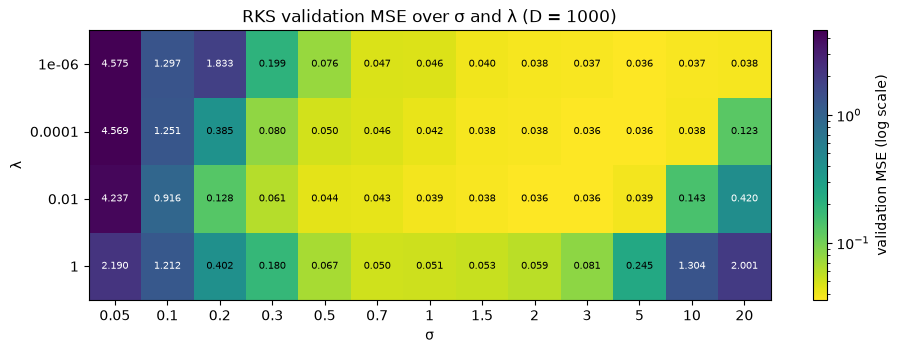

In [7]:
from matplotlib.colors import LogNorm

lambdas = [1e-6, 1e-4, 1e-2, 1]
grid_val = np.zeros((len(lambdas), len(sigmas)))
for i, lam in enumerate(lambdas):
    for j, sigma in enumerate(sigmas):
        model = RandomKitchenSinks(D=1000, sigma=sigma, ridge_lambda=lam).fit(ds.train.X, ds.train.y)
        grid_val[i, j] = mse(ds.val.y, model.predict(ds.val.X))
    print(f"lambda = {lam:g}: best sigma {sigmas[int(np.argmin(grid_val[i]))]} (val MSE {grid_val[i].min():.4f})")

fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(grid_val, norm=LogNorm(), cmap="viridis_r", aspect="auto")
for i in range(len(lambdas)):
    for j in range(len(sigmas)):
        v = grid_val[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7,
                color="white" if im.norm(v) > 0.5 else "black")
ax.set_xticks(range(len(sigmas)), labels=sigmas)
ax.set_yticks(range(len(lambdas)), labels=[f"{lam:g}" for lam in lambdas])
ax.set_xlabel("σ")
ax.set_ylabel("λ")
ax.set_title("RKS validation MSE over σ and λ (D = 1000)")
fig.colorbar(im, ax=ax, label="validation MSE (log scale)")
plt.show()


### c: 1-Hidden Layer MLP

Parameters for sweep: smaller dataset, so more epochs
- Adam optimizer with learning rate 1e-3
- Batch size = 128 (smaller than in previous questions)
- Patience = 200 to offset the smaller epoch size

We sweep over the size of the hidden layer (widths 2, 4, 8, ..., 2048)

In [8]:
class MLP(nn.Module):
    """One-hidden-layer MLP for regression, trained with Adam and early stopping on validation MSE."""
    def __init__(self, d_in=2, d_hidden=128, lr=1e-3, batch_size=128, max_epochs=5000, patience=200, seed=0):
        super().__init__()
        torch.manual_seed(seed)
        self.net = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, 1))
        self.lr, self.batch_size, self.max_epochs, self.patience = lr, batch_size, max_epochs, patience

    def forward(self, X):
        return self.net(X).squeeze(1)                                    # shape [n], not [n, 1]

    def fit(self, X, y, X_val, y_val):
        X, y = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
        X_val, y_val = torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)
        optimizer = torch.optim.Adam(self.parameters(), lr=self.lr)
        loss_fn = nn.MSELoss()

        n = len(X)
        best_val, best_state, epochs_without_improvement = np.inf, None, 0
        self.history = {"train": [], "val": []}

        for epoch in range(self.max_epochs):
            self.train()
            perm = torch.randperm(n)
            for start in range(0, n, self.batch_size):
                idx = perm[start:start + self.batch_size]
                loss = loss_fn(self(X[idx]), y[idx])
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # End of epoch: MSE on the full training and validation sets with the current weights
            self.eval()
            with torch.no_grad():
                self.history["train"].append(loss_fn(self(X), y).item())
                self.history["val"].append(loss_fn(self(X_val), y_val).item())

            val_mse = self.history["val"][-1]
            if val_mse < best_val - 1e-4:
                best_val = val_mse
                best_state = copy.deepcopy(self.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= self.patience:
                    break

        self.load_state_dict(best_state)
        self.best_epoch = int(np.argmin(self.history["val"])) + 1
        self.n_epochs = epoch + 1
        return self

    def predict(self, X):
        self.eval()
        with torch.no_grad():
            return self(torch.tensor(X, dtype=torch.float32)).numpy()   # flat NumPy array, shape (n,)

In [9]:
widths = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]
mlp_mse = {"train": [], "val": []}
mlp_models = {}

for width in widths:
    model = MLP(d_hidden=width).fit(ds.train.X, ds.train.y, ds.val.X, ds.val.y)
    mlp_models[width] = model
    mlp_mse["train"].append(mse(ds.train.y, model.predict(ds.train.X)))
    mlp_mse["val"].append(mse(ds.val.y, model.predict(ds.val.X)))
    print(f"width {width:>4}: {model.n_epochs:>4} epochs (best {model.best_epoch:>4}) | "
          f"train MSE {mlp_mse['train'][-1]:.4f} | val MSE {mlp_mse['val'][-1]:.4f}")

best_width = widths[int(np.argmin(mlp_mse["val"]))]
best_mlp = mlp_models[best_width]
print(f"\nbest width (lowest validation MSE): {best_width}")

width    2: 4516 epochs (best 4348) | train MSE 0.2883 | val MSE 0.2874
width    4: 1270 epochs (best 1225) | train MSE 0.3125 | val MSE 0.3380
width    8: 4178 epochs (best 4142) | train MSE 0.0458 | val MSE 0.0483
width   16: 1811 epochs (best 1703) | train MSE 0.0341 | val MSE 0.0401
width   32: 1645 epochs (best 1445) | train MSE 0.0322 | val MSE 0.0401
width   64:  998 epochs (best  798) | train MSE 0.0325 | val MSE 0.0395
width  128:  881 epochs (best  681) | train MSE 0.0307 | val MSE 0.0385
width  256:  704 epochs (best  632) | train MSE 0.0305 | val MSE 0.0386
width  512:  595 epochs (best  427) | train MSE 0.0299 | val MSE 0.0381
width 1024:  475 epochs (best  275) | train MSE 0.0298 | val MSE 0.0377
width 2048:  385 epochs (best  185) | train MSE 0.0310 | val MSE 0.0369

best width (lowest validation MSE): 2048


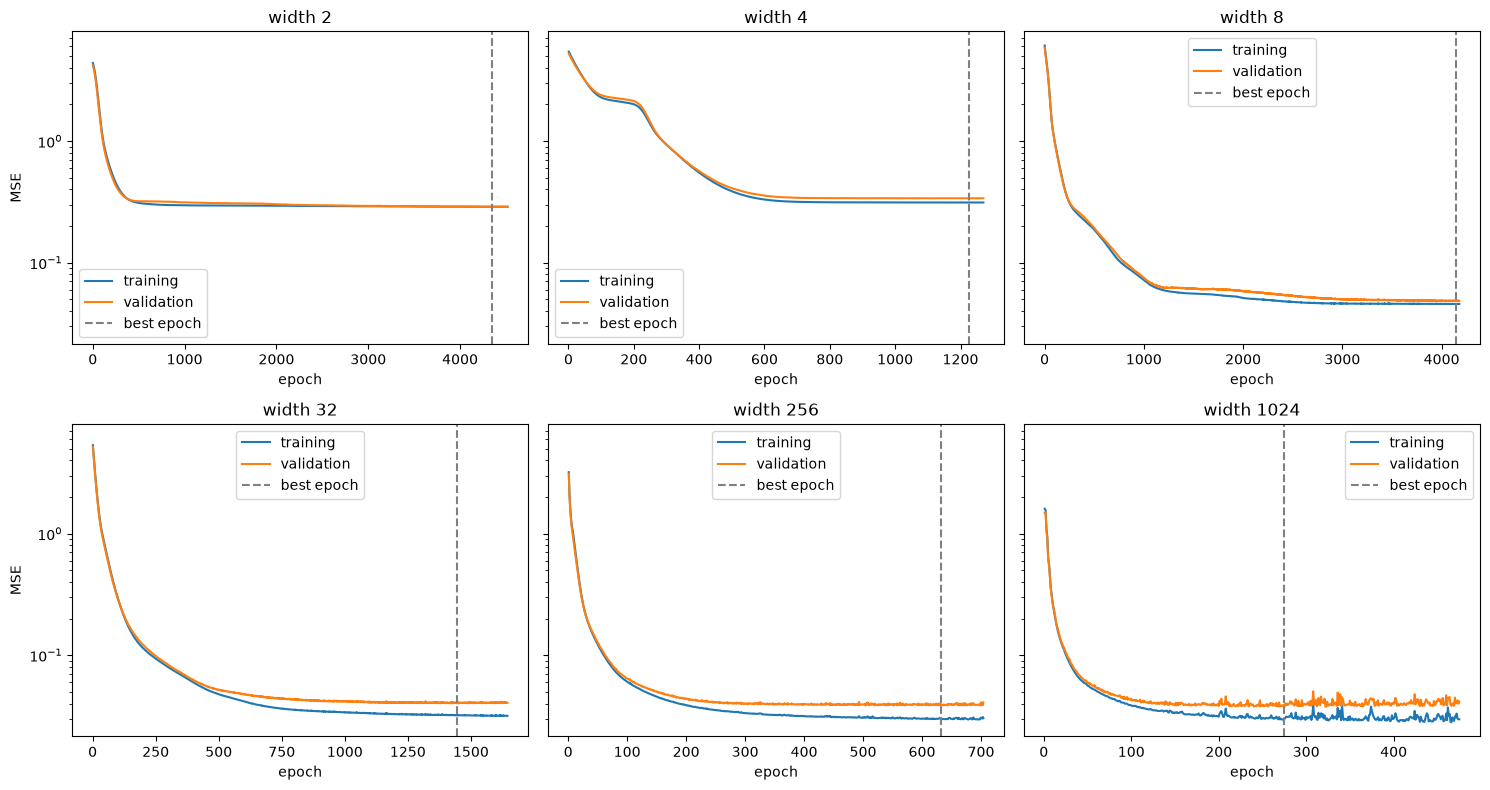

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, width in zip(axes.flat, [2, 4, 8, 32, 256, 1024]):
    h = mlp_models[width].history
    ax.plot(np.arange(1, len(h["train"]) + 1), h["train"], label="training")
    ax.plot(np.arange(1, len(h["val"]) + 1), h["val"], label="validation")
    ax.axvline(mlp_models[width].best_epoch, color="gray", linestyle="--", label="best epoch")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_title(f"width {width}")
    ax.legend()
for ax in axes[:, 0]:
    ax.set_ylabel("MSE")
plt.tight_layout()
plt.show()

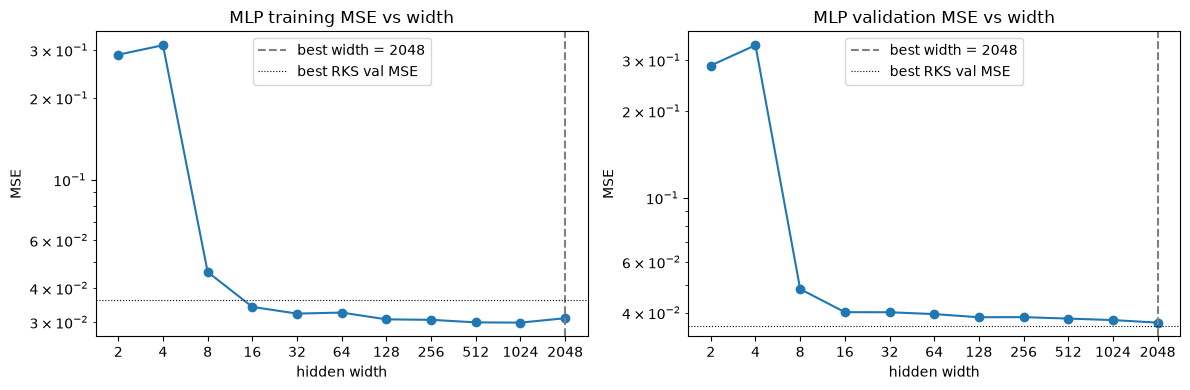

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ["train", "val"]):
    ax.plot(widths, mlp_mse[split], marker="o")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(widths, labels=widths)
    ax.set_xlabel("hidden width")
    ax.set_ylabel("MSE")
    ax.axvline(best_width, color="gray", linestyle="--", label=f"best width = {best_width}")
    ax.axhline(min(rks_mse["val"]), color="black", linestyle=":", linewidth=0.8, label="best RKS val MSE")
    ax.legend()
axes[0].set_title("MLP training MSE vs width")
axes[1].set_title("MLP validation MSE vs width")
plt.tight_layout()
plt.show()

The models keep getting slightly better, the bigger they get, once they get past the threshold where they have learned the necessary relationships (beyond a certain point, they are more complicated than necessary). The patience parameter prevents overfitting to the training data. For widths 2, 4, 8, we see underfitting.

Size 2 being better than size 4 could just be due to the random seed we used.

For part d, we choose 2048 as the size of the hidden layer.

### d: Comparison and visualization

In [12]:
final_rks = RandomKitchenSinks(D=1000, sigma=5, ridge_lambda=1e-3).fit(ds.train.X, ds.train.y)
final_mlp = MLP(d_hidden=2048).fit(ds.train.X, ds.train.y, ds.val.X, ds.val.y)

for name, model in [("RKS", final_rks), ("MLP", final_mlp)]:
    print(f"{name}: train MSE {mse(ds.train.y, model.predict(ds.train.X)):.4f} | "
          f"val MSE {mse(ds.val.y, model.predict(ds.val.X)):.4f}")
print(f"predict-the-training-mean: val MSE {mse(ds.val.y, ds.train.y.mean()):.4f}")

RKS: train MSE 0.0347 | val MSE 0.0360
MLP: train MSE 0.0310 | val MSE 0.0369
predict-the-training-mean: val MSE 2.3966


In [13]:
test_preds = {"rks": final_rks.predict(ds.test.X), "mlp": final_mlp.predict(ds.test.X)}

for name, preds in test_preds.items():
    filename = f"{name}_test_predictions.csv"
    np.savetxt(filename, preds, fmt="%.6f")
    check = np.loadtxt(filename)
    print(f"{filename}: {check.shape[0]} rows | NaNs: {np.isnan(check).sum()} | "
          f"range {check.min():.2f} to {check.max():.2f}")

print(f"\nRMS difference between RKS and MLP test predictions: "
      f"{np.sqrt(np.mean((test_preds['rks'] - test_preds['mlp']) ** 2)):.4f}")

rks_test_predictions.csv: 200 rows | NaNs: 0 | range -1.05 to 5.19
mlp_test_predictions.csv: 200 rows | NaNs: 0 | range -0.99 to 5.09

RMS difference between RKS and MLP test predictions: 0.0696


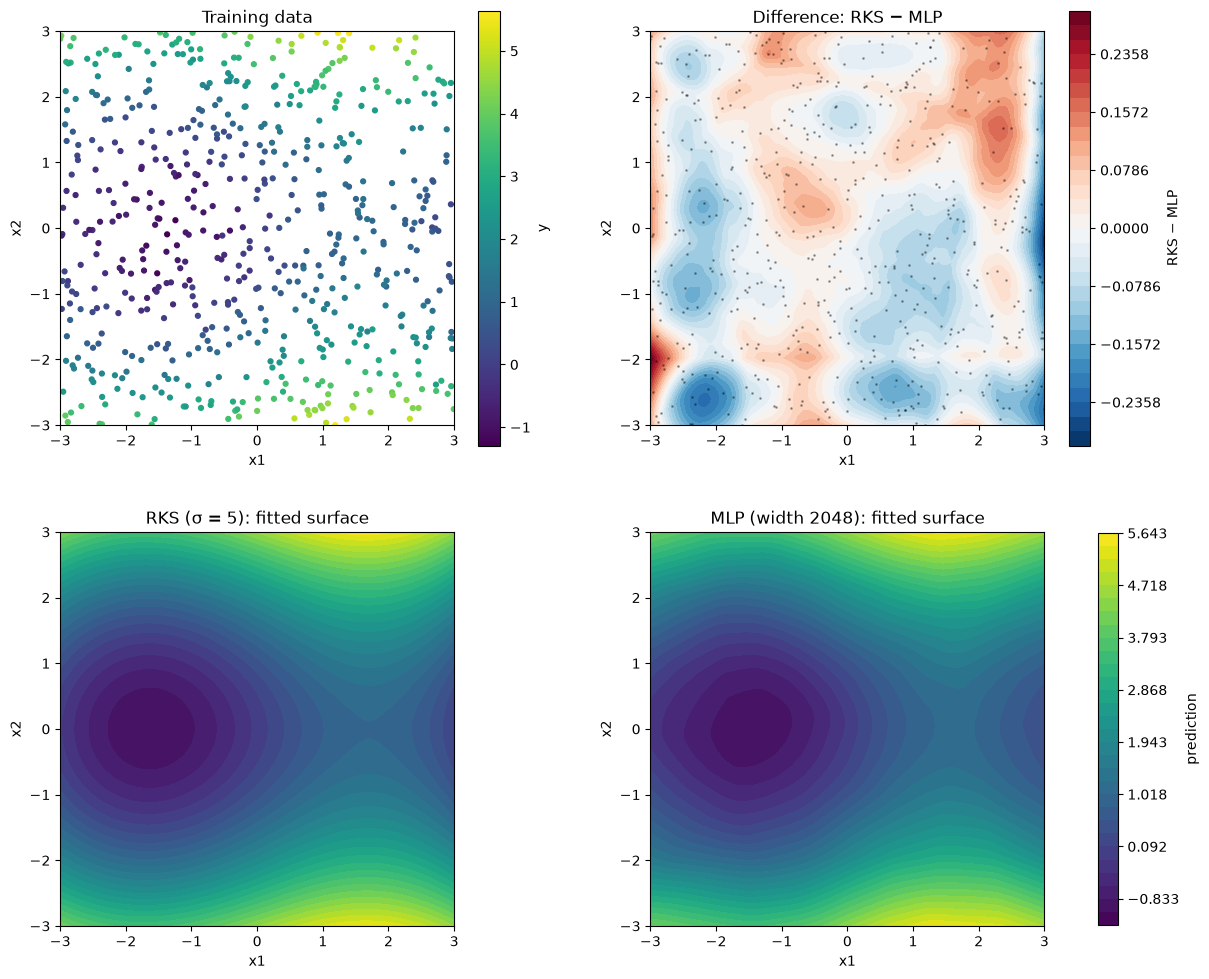

In [14]:
grid = 200
xs = np.linspace(-3, 3, grid)
X1, X2 = np.meshgrid(xs, xs)
X_grid = np.column_stack([X1.ravel(), X2.ravel()])
surfaces = {"RKS (σ = 5)": final_rks.predict(X_grid).reshape(grid, grid),
            "MLP (width 2048)": final_mlp.predict(X_grid).reshape(grid, grid)}

vmin = min(ds.train.y.min(), *(Z.min() for Z in surfaces.values()))
vmax = max(ds.train.y.max(), *(Z.max() for Z in surfaces.values()))
levels = np.linspace(vmin, vmax, 31)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")

# Top left: training data
points = axes[0, 0].scatter(ds.train.X[:, 0], ds.train.X[:, 1], c=ds.train.y, cmap="viridis",
                            vmin=vmin, vmax=vmax, s=12)
axes[0, 0].set_title("Training data")
fig.colorbar(points, ax=axes[0, 0], label="y")

# Top right: difference between the two fitted surfaces
diff = surfaces["RKS (σ = 5)"] - surfaces["MLP (width 2048)"]
lim = np.abs(diff).max()
diff_plot = axes[0, 1].contourf(X1, X2, diff, levels=np.linspace(-lim, lim, 31), cmap="RdBu_r")
axes[0, 1].scatter(ds.train.X[:, 0], ds.train.X[:, 1], s=1, color="black", alpha=0.3)
axes[0, 1].set_title("Difference: RKS − MLP")
fig.colorbar(diff_plot, ax=axes[0, 1], label="RKS − MLP")

# Bottom row: the two fitted surfaces, on the same color scale as the data
for ax, (name, Z) in zip(axes[1], surfaces.items()):
    filled = ax.contourf(X1, X2, Z, levels=levels, cmap="viridis")
    ax.set_title(f"{name}: fitted surface")
fig.colorbar(filled, ax=axes[1, :], label="prediction", shrink=0.9)

for ax in axes.flat:
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
fig.get_layout_engine().set(wspace=0.08)
plt.show()

Qualitatively, the RKS model is much smoother! If the data generating processes were that smooth than this is probably the better model here (and indeed it does slightly better on the validation test set). But both are quite good overall - they recover the color distribution from the plot in part a.